# CelebA Ablation: Initial Particle Distribution (DR Target, Riesz MMD Flow, Female Arm)

The method notebook `CelebA_DR_Riesz_MMD_Flow_AdamW_Female` starts the particles at the
encoded observed arm, $P_{Y \mid A = a^\*}$. This ablation holds that pipeline fixed — same
data, SD-VAE latents, cross-fitted DR target, kernel, learning-rate schedule and iteration
budget — and varies only where the particles begin:

1. **observed arm** $P_{Y \mid A = a^\*}$ — the method notebook's choice, kept as the reference;
2. **logged marginal** $P_Y$ — all logged latents, both arms, ignoring the treatment;
3. $\mathcal N(0, I)$ in the standardised latent space;
4. $\mathcal N(\hat\mu, \hat\Sigma)$ with the empirical mean and covariance of the latents.

The objective constrains only the *mean embedding* of the particle cloud, so nothing in it
requires the particles to lie on the VAE's latent manifold. The question is whether an
initialisation that is off that manifold can still decode to faces once the embedding is
matched — the same question the ColorMNIST init ablation asks, in a much higher-dimensional
latent.

Two features of this latent space make the comparison sharper than its ColorMNIST analogue.
The flow operates on **standardised** coordinates, so $\mathcal N(0, I)$ already carries the
correct per-coordinate mean and variance: it is a genuinely strong baseline, differing from
$\mathcal N(\hat\mu, \hat\Sigma)$ only in the *correlations* between coordinates. And with
$d = 4096$ latent dimensions but $n = 2048$ logged images, the empirical covariance is
singular (rank at most $n - 1$), so $\mathcal N(\hat\mu, \hat\Sigma)$ is sampled exactly
within the span of the data rather than through a ridge-regularised Cholesky factor.

In [1]:
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt

sys.path.append("../../src")
torch.set_default_dtype(torch.float32)

from data_utils import binary_stats, load_celeba_paper
from data_utils.celeba import to_image_range
from autoencoder_utils import decode_latents, encode_images, load_sd_vae
from causality_utils import (cpme_dr_weights_crossfit, make_crossfit_fold_ids,
                             select_regularization)
from dens_ratio_utils import crossfit_propensity
from mmd_flow_utils import adamw_riesz_flow
from metric_utils import sliced_wasserstein

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 1. Data, Latents, and the Cross-Fitted DR Target

Identical to the method notebook: the controlled observational sample ($n = 2048$ at
$256 \times 256$), frozen SD-VAE latents standardised per coordinate, and the cross-fitted
one-step DR weights on one shared 5-fold split.

In [2]:
TARGET_A = 0
N_ITER = 4000
CACHE = "../../data/celeba_dgp/celeba_paper_256_n2048_nref2000_seed0.pt"
CELEBA_ROOT = "/nfs/ghome/live/danceh/data/celeba"   # machine-local; used only to (re)generate

data = load_celeba_paper(CACHE, root=CELEBA_ROOT, seed=0, image_size=256,
                         n_obs=2048, n_ref=2000, verbose=False)
A = data["A"].view(-1).long()
X = data["X"].view(-1).long()
Y = data["Y"]
Y_ref = data[f"Y{TARGET_A}_ref"]
arm = A == TARGET_A

vae = load_sd_vae(device)
Z = encode_images(vae, Y)
Z_ref = encode_images(vae, Y_ref)
latent_mean = Z.mean(dim=0, keepdim=True)
latent_std = Z.std(dim=0, keepdim=True).clamp_min(1e-3)
to_flow = lambda z: (z - latent_mean) / latent_std
from_flow = lambda p: p * latent_std + latent_mean
Z_std, Z_ref_std = to_flow(Z), to_flow(Z_ref)
print(f"arm a={TARGET_A} size = {int(arm.sum())}   latents {tuple(Z.shape)}")

/nfs/ghome/live/bbozkurt/.conda/envs/torchnn/lib/python3.12/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


arm a=0 size = 1126   latents (2048, 4096)


In [3]:
n = len(A)
fold_ids = make_crossfit_fold_ids(n, n_folds=5, seed=0)
torch.manual_seed(SEED)
e1 = crossfit_propensity(X.double().unsqueeze(1), A.double(), fold_ids)
w_hat = (A == TARGET_A).double() / (e1 if TARGET_A == 1 else 1.0 - e1)

K_x = (X[:, None] == X[None, :]).double()
K_a = (A[:, None] == A[None, :]).double()
K_a_target = (A == TARGET_A).double()[:, None].expand(n, n).contiguous()
K_pair = K_x * K_a
fold_lambdas = {}
for fold in np.unique(fold_ids):
    train = np.where(fold_ids != fold)[0]
    fold_lambdas[int(fold)], _ = select_regularization(K_pair[train][:, train],
                                                       Z_std[train, 0].double().cpu(), seed=0)
v_dr = cpme_dr_weights_crossfit(K_x, K_a, K_a_target, w_hat, fold_ids,
                                fold_lambdas).float().to(device)
arm_indices = torch.nonzero(arm).ravel()
M = min(1024, len(arm_indices))
print(f"DR weights: sum(v) = {v_dr.sum():.3f}   sum|v| = {v_dr.abs().sum():.3f}   "
      f"sum(v X) = {(v_dr.cpu() * X.float()).sum():.3f}")
print(f"M = {M} particles")

DR weights: sum(v) = 1.000   sum|v| = 1.000   sum(v X) = 0.300
M = 1024 particles


## 2. The Four Initial Distributions

$\mathcal N(\hat\mu, \hat\Sigma)$ is drawn as $\hat\mu + C^\top g / \sqrt{n-1}$ with $C$ the
centred latent matrix and $g \sim \mathcal N(0, I_n)$. This has covariance
$C^\top C / (n-1) = \hat\Sigma$ exactly and needs no regularisation, at the cost of placing
every draw in the $2047$-dimensional span of the data — which is the honest meaning of a
moment-matched Gaussian when $d > n$.

Decoding the raw initial particles, before any flow is run, shows what each starting point
looks like as an image.

observed arm       mean |z| =    62.7   per-coordinate std = 0.981
logged marginal    mean |z| =    63.4   per-coordinate std = 0.996
N(0, I)            mean |z| =    64.0   per-coordinate std = 0.999
N(mu, Sigma)       mean |z| =    63.2   per-coordinate std = 0.993


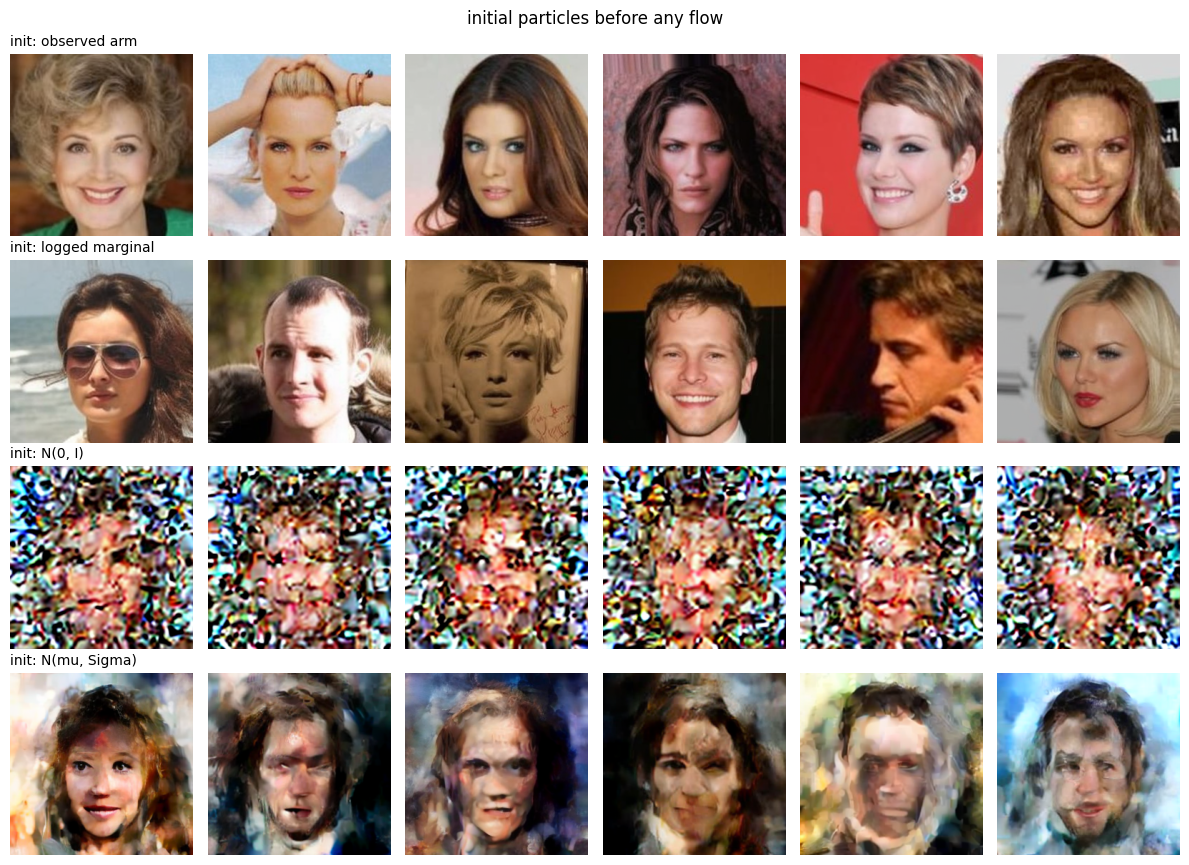

In [4]:
generator = lambda offset: torch.Generator(device=device).manual_seed(SEED + offset)
pick_arm = arm_indices[torch.randperm(len(arm_indices),
                                      generator=torch.Generator().manual_seed(SEED))[:M]]
pick_all = torch.randperm(n, generator=torch.Generator().manual_seed(SEED + 7))[:M]

centred = Z_std - Z_std.mean(dim=0, keepdim=True)
weights_g = torch.randn(M, n, generator=generator(2), device=device)
gaussian_moment_matched = (Z_std.mean(dim=0, keepdim=True)
                           + weights_g @ centred / (n - 1) ** 0.5)

initials = {
    "observed arm": Z_std[pick_arm].clone(),
    "logged marginal": Z_std[pick_all].clone(),
    "N(0, I)": torch.randn(M, Z_std.shape[1], generator=generator(3), device=device),
    "N(mu, Sigma)": gaussian_moment_matched,
}
for name, z0 in initials.items():
    print(f"{name:18s} mean |z| = {z0.norm(dim=1).mean():7.1f}   "
          f"per-coordinate std = {z0.std(dim=0).mean():.3f}")

n_show = 6
fig, axes = plt.subplots(len(initials), n_show, figsize=(2.0 * n_show, 2.2 * len(initials)))
with torch.no_grad():
    for row, (name, z0) in enumerate(initials.items()):
        decoded = decode_latents(vae, from_flow(z0[:n_show]), 256)
        for column in range(n_show):
            axes[row, column].imshow(to_image_range(decoded[column]).permute(1, 2, 0).numpy())
            axes[row, column].axis("off")
        axes[row, 0].set_title(f"init: {name}", fontsize=10, loc="left")
fig.suptitle("initial particles before any flow", fontsize=12)
fig.tight_layout()
plt.show()

## 3. One Flow per Initialisation

Same target, kernel, learning rate, warm-up and cosine schedule, and iteration budget for all
four. The latent sliced Wasserstein-2 distance to the encoded references is tracked along each
flow, with the reference-split floor for calibration.

observed arm       loss  63.8875 ->  63.6414   mean transport    4.52


logged marginal    loss  63.4866 ->  63.6741   mean transport   15.30


N(0, I)            loss  63.2876 ->  63.7088   mean transport   46.04


N(mu, Sigma)       loss  63.6150 ->  63.6981   mean transport   28.05


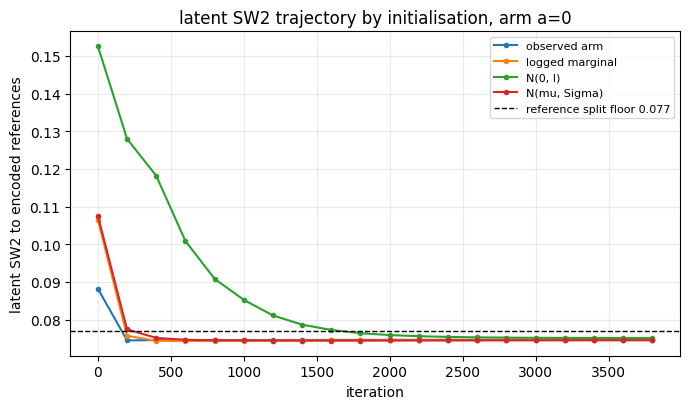

In [5]:
flowed, histories = {}, {}
for name, z0 in initials.items():
    torch.manual_seed(1)
    flowed[name], histories[name] = adamw_riesz_flow(
        z0.clone(), Z_std, target_weights=v_dr, sliced=False, n_iterations=N_ITER,
        learning_rate=0.001, warmup_steps=100, lr_schedule="cosine",
        snapshot_every=200, verbose=False)
    print(f"{name:18s} loss {histories[name]['loss'][0]:8.4f} -> "
          f"{histories[name]['loss'][-1]:8.4f}   mean transport "
          f"{(flowed[name] - z0).norm(dim=1).mean():7.2f}")

latent_floor = sliced_wasserstein(Z_ref_std[:1000], Z_ref_std[1000:], p=2, seed=0).item()
plt.figure(figsize=(7, 4.2))
for name in initials:
    steps = sorted(histories[name]["snapshots"])
    curve = [sliced_wasserstein(histories[name]["snapshots"][s], Z_ref_std, p=2, seed=0).item()
             for s in steps]
    plt.plot(steps, curve, marker="o", ms=3, label=name)
plt.axhline(latent_floor, ls="--", c="k", lw=1, label=f"reference split floor {latent_floor:.3f}")
plt.xlabel("iteration")
plt.ylabel("latent SW2 to encoded references")
plt.title(f"latent SW2 trajectory by initialisation, arm a={TARGET_A}")
plt.legend(fontsize=8)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 4. Decoded Samples After the Flow

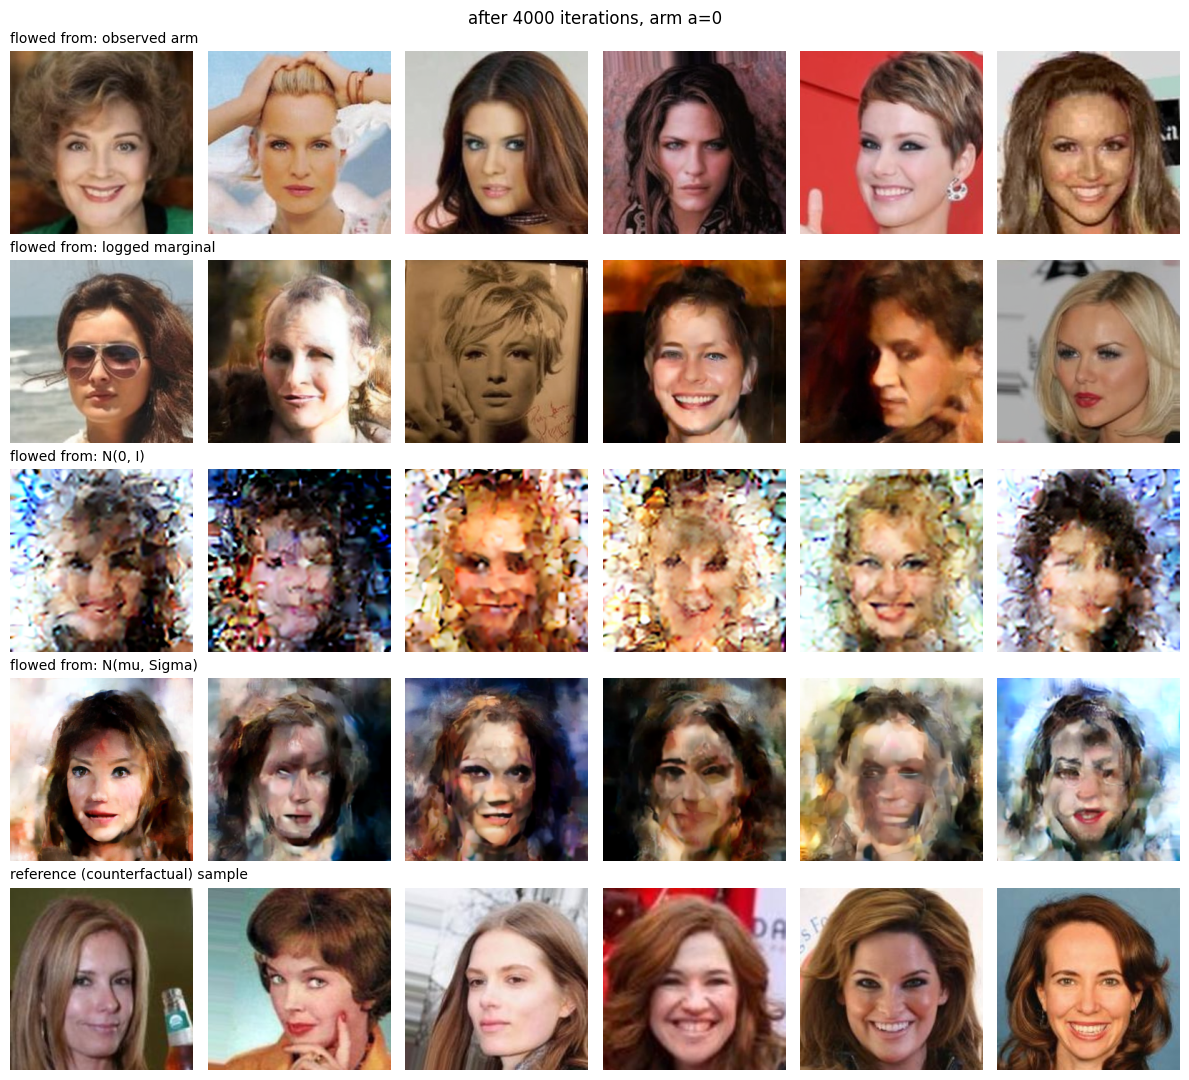

In [6]:
decoded_flowed = {}
with torch.no_grad():
    for name, particles in flowed.items():
        decoded_flowed[name] = decode_latents(vae, from_flow(particles), 256)

fig, axes = plt.subplots(len(initials) + 1, n_show,
                         figsize=(2.0 * n_show, 2.2 * (len(initials) + 1)))
for row, (name, images) in enumerate(decoded_flowed.items()):
    for column in range(n_show):
        axes[row, column].imshow(to_image_range(images[column]).permute(1, 2, 0).numpy())
        axes[row, column].axis("off")
    axes[row, 0].set_title(f"flowed from: {name}", fontsize=10, loc="left")
ref_pick = torch.randperm(len(Y_ref), generator=torch.Generator().manual_seed(2))[:n_show]
for column in range(n_show):
    axes[-1, column].imshow(to_image_range(Y_ref[ref_pick][column]).permute(1, 2, 0).numpy())
    axes[-1, column].axis("off")
axes[-1, 0].set_title("reference (counterfactual) sample", fontsize=10, loc="left")
fig.suptitle(f"after {N_ITER} iterations, arm a={TARGET_A}", fontsize=12)
fig.tight_layout()
plt.show()

## 5. Metric Evaluation

Pixel-space distances follow the protocol of Dance et al. (2026): decoded samples against the
2000 held-out reference images. Two further columns diagnose *where* a flow ends up rather
than how far: the latent distance to the encoded references, and the **cycle error**
$\lVert \mathrm{enc}(\mathrm{dec}(z)) - z\rVert$, which measures how far a particle sits from
the VAE's latent manifold — a particle the decoder cannot render faithfully will not survive
a decode-encode round trip. The observed arm's own latents give the reference value.

In [7]:
flatten = lambda images: images.reshape(images.shape[0], -1)


@torch.no_grad()
def cycle_error(particles):
    return (to_flow(encode_images(vae, decode_latents(vae, from_flow(particles), 256)))
            - particles).norm(dim=1).mean().item()


print(f"{'initialisation':18s} {'start SW2':>10s} {'end SW2':>9s} {'pixel SW2':>10s} "
      f"{'pixel SW1':>10s} {'cycle':>8s}")
for name in initials:
    start = sliced_wasserstein(initials[name], Z_ref_std, p=2, seed=0).item()
    end = sliced_wasserstein(flowed[name], Z_ref_std, p=2, seed=0).item()
    images = decoded_flowed[name]                     # metrics on raw [-1,1] pixels
    sw2 = sliced_wasserstein(flatten(images), flatten(Y_ref), p=2, seed=0).item()
    sw1 = sliced_wasserstein(flatten(images), flatten(Y_ref), p=1, seed=0).item()
    print(f"{name:18s} {start:10.4f} {end:9.4f} {sw2:10.4f} {sw1:10.4f} "
          f"{cycle_error(flowed[name]):8.2f}")

observed_images = Y[arm_indices]
reference_images = Y_ref
print(f"{'observed arm (base)':18s} {'-':>10s} {'-':>9s} "
      f"{sliced_wasserstein(flatten(observed_images), flatten(reference_images), p=2, seed=0).item():10.4f} "
      f"{sliced_wasserstein(flatten(observed_images), flatten(reference_images), p=1, seed=0).item():10.4f} "
      f"{cycle_error(initials['observed arm']):8.2f}")
print(f"{'reference floor':18s} {latent_floor:10.4f} {'-':>9s} "
      f"{sliced_wasserstein(flatten(reference_images[:1000]), flatten(reference_images[1000:]), p=2, seed=0).item():10.4f} "
      f"{sliced_wasserstein(flatten(reference_images[:1000]), flatten(reference_images[1000:]), p=1, seed=0).item():10.4f} "
      f"{'-':>8s}")

initialisation      start SW2   end SW2  pixel SW2  pixel SW1    cycle


observed arm           0.0882    0.0747     0.0376     0.0261     7.69


logged marginal        0.1065    0.0746     0.0369     0.0256     9.42


N(0, I)                0.1526    0.0751     0.0759     0.0596    13.56


N(mu, Sigma)           0.1076    0.0745     0.0441     0.0324    11.45


observed arm (base)          -         -     0.0521     0.0395     7.42


reference floor        0.0769         -     0.0399     0.0276        -


## Summary

- **Every initialisation matches the target embedding equally well.** The latent distance
  to the encoded references ends at $0.0745$–$0.0751$ for all four starts (reference-split
  floor $0.0769$), and the final Riesz losses agree to within $0.07$. Read only through the
  objective it optimises, the sampler is indifferent to where it began.
- **Decoded quality nevertheless differs by a factor of two.** Pixel SW2: logged marginal
  $0.0369$ and observed arm $0.0376$, both at or below the $0.0399$ reference floor;
  $\mathcal N(\hat\mu, \hat\Sigma)$ $0.0441$; $\mathcal N(0, I)$ $0.0759$ — worse than the
  $0.0521$ of the observational sample with no flow at all. The Gaussian starts reach the
  right mean embedding by decoding to faces that are visibly smeared or shattered.
- **The cycle error explains the ordering exactly.** $\lVert \mathrm{enc}(\mathrm{dec}(z)) - z\rVert$
  is $7.69$, $9.42$, $11.45$, $13.56$ for observed, marginal,
  $\mathcal N(\hat\mu, \hat\Sigma)$, $\mathcal N(0, I)$ — monotone in the pixel metric, and
  against $7.42$ for the raw observed latents. Matching a mean embedding does **not** place
  particles on the decoder's latent manifold; a flow started off it stays off it.
- **Moment matching is not sufficient.** $\mathcal N(\hat\mu, \hat\Sigma)$ carries the exact
  mean *and* covariance of the latents, and in standardised coordinates $\mathcal N(0, I)$
  already carries the exact per-coordinate moments. Neither reproduces the manifold: the
  gap between the two Gaussians is the between-coordinate correlation structure, and the gap
  between both and the logged starts is everything beyond second order.
- **The logged marginal's aggregate score hides a degraded subgroup — do not read it as a
  recommendation.** $P_Y$ starts $464$ of its $1024$ particles at male images, which the flow
  must transport across to the female region. Splitting the flowed sample by the arm each
  particle came from (measured separately, outside this notebook): female-origin particles
  score $0.0586$ with cycle error $7.51$, male-origin ones $0.0898$ with cycle error $11.73$
  — the male-origin half is markedly worse on both, and its decoded faces are the ones that
  look wrong. Increasing the iteration budget ($8000$, $12000$) or the learning rate does not
  repair it; those particles are over-transported rather than stranded. The aggregate
  $0.0369$ is therefore a distributional artefact of averaging a good half with a bad half,
  not evidence that $P_Y$ is the better start.
- **Recommendation.** Initialise from the treated arm $P_{Y \mid A = a^\*}$. The logged
  marginal is defensible only if its male-origin subgroup is checked separately. Do not
  initialise from a Gaussian, even a moment-matched one; in this latent it costs more than
  skipping the flow entirely.